# Olist — EDA e auditoria temporal (TASK 02)

Ciência dos Dados (T326), UNIFOR. Os scripts reproduzíveis estão em `src/olist_modeling/`. Este notebook consulta resultados reais já gerados; não ajusta transformadores/modelos. **EDA restrita ao treino com rótulos disponíveis antes de 15/04/2018.**

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/olist_modeling").is_dir())
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), "Selecione Python (Olist .venv)"
TABLES = ROOT / "resultados/tabelas/task02"
FIGURES = ROOT / "resultados/graficos/task02"
read_json = lambda name: json.loads((TABLES / name).read_text(encoding="utf-8"))
print("Ambiente:", sys.version.split()[0], "| kernel Olist local")

Ambiente: 3.13.6 | kernel Olist local


## Coorte, disponibilidade e cortes

Unidade: pedido; alvo: dias fracionários compra–recebimento. Coorte somente de entregues. Eventos posteriores e IDs não são features. A vigência histórica dos cadastros não pode ser provada pelo dump. Rótulos ainda desconhecidos nos cortes foram purgados; isso também introduz viés de maturação.

In [2]:
scope = read_json("eda_scope.json")
audit = read_json("source_audit.json")
assert audit["passed"] and not scope["test_used"]
print(scope)
display(pd.read_csv(TABLES / "split_summary.csv"))
display(pd.read_csv(TABLES / "label_maturation_diagnostic.csv"))
display(pd.read_csv(TABLES / "feature_temporal_audit.csv"))

{'geographic_min_orders': 20, 'outliers_removed': 0, 'purchase_max': '2018-04-13 13:01:55', 'purchase_min': '2016-09-15 12:16:38', 'rows': 64401, 'scope': 'somente treino com rótulo conhecido antes da validação', 'test_used': False}


,split,rows,cohort_pct,purchase_min,purchase_max,delivery_max,label_cutoff_exclusive
0,train_candidates,67379,69.844511,2016-09-15 12:16:38,2018-04-14 23:28:11,2018-09-19 23:24:07,2018-04-15 00:00:00
1,train,64401,66.757541,2016-09-15 12:16:38,2018-04-13 13:01:55,2018-04-14 22:04:08,2018-04-15 00:00:00
2,validation_candidates,14606,15.140458,2018-04-15 00:08:41,2018-06-20 23:39:24,2018-10-17 13:22:46,2018-06-21 00:00:00
3,validation,12675,13.138800,2018-04-15 00:08:41,2018-06-19 13:09:39,2018-06-20 23:58:37,2018-06-21 00:00:00
4,test,14485,15.015031,2018-06-21 00:22:02,2018-08-29 15:00:37,2018-10-02 00:18:50,snapshot final; data de extração desconhecida
5,final_train,80043,82.971908,2016-09-15 12:16:38,2018-06-19 13:09:39,2018-06-20 23:58:37,2018-06-21 00:00:00


,segment,label_unavailable_at_cutoff,orders,mean_days,median_days,max_days
0,train,False,64401,13.364500,11.264236,209.628611
1,train,True,2978,23.873846,18.719184,208.351759
2,validation,False,12675,10.388468,8.508657,57.281713
3,validation,True,1931,13.895885,10.821076,143.411435


,feature,source,definition,future_outcome_used,availability,limitation
0,products_value_total,items.price,Soma dos preços dos itens; BRL.,False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
1,freight_value_total,items.freight_value,Soma do frete dos itens; BRL.,False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
2,order_value_total,"items.price, items.freight_value",Produtos + frete; não usa pagamentos.,False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
3,items_count,items.order_item_id,"Número de linhas de itens, não máximo do seque...",False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
4,products_count,items.product_id,Quantidade de produtos distintos no carrinho.,False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
5,sellers_count,items.seller_id,Quantidade de vendedores distintos.,False,"compra, sob hipóteses documentadas",Carrinho no registro da compra; dump não regis...
6,seller_states_count,sellers.seller_state,Quantidade de UFs dos vendedores.,False,"compra, sob hipóteses documentadas",Cadastro sem histórico: vigência na compra ass...
7,same_state_items_fraction,"customers.customer_state, sellers.seller_state",Fração de itens com vendedor na UF do comprador.,False,"compra, sob hipóteses documentadas",Cadastro sem histórico: vigência na compra ass...
8,weight_g_total,products.product_weight_g,Soma por item; ausente se houver peso ausente/...,False,"compra, sob hipóteses documentadas",Cadastro sem histórico: vigência na compra ass...
9,weight_g_mean,products.product_weight_g,Média dos pesos conhecidos por item.,False,"compra, sob hipóteses documentadas",Cadastro sem histórico: vigência na compra ass...


## Distribuições, ausências e extremos

Histogramas mantêm os extremos; valor e peso usam eixo logarítmico. IQR é diagnóstico e não remove pedidos. O alcance das previsões permanece condicionado à entrega observada.

,feature,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,products_value_total,64401,135.064239,204.838042,2.290000,11.970000,45.900000,84.990000,149.900000,395.900000,977.500000,1.344000e+04
1,freight_value_total,64401,21.945597,19.549244,0.000000,7.780000,13.930000,16.600000,23.480000,50.850000,96.630000,1.002290e+03
2,order_value_total,64401,157.009836,213.728806,10.070000,22.790000,61.050000,103.360000,174.160000,433.130000,1034.340000,1.366408e+04
3,items_count,64401,1.142715,0.541124,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,3.000000,2.100000e+01
4,products_count,64401,1.038027,0.223533,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,7.000000e+00
5,sellers_count,64401,1.012065,0.114996,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,5.000000e+00
6,seller_states_count,64401,1.004705,0.069557,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000e+00
7,same_state_items_fraction,64401,0.349052,0.476098,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000e+00
8,weight_g_total,64385,2448.898734,4889.130302,2.000000,100.000000,300.000000,800.000000,2133.000000,10700.000000,22600.000000,1.844000e+05
9,weight_g_mean,64385,2156.458674,3850.790805,2.000000,100.000000,300.000000,700.000000,1850.000000,9750.000000,19108.000000,4.042500e+04


,feature,missing,missing_pct
8,weight_g_total,16,0.024844
9,weight_g_mean,16,0.024844
10,volume_cm3_total,16,0.024844
11,length_cm_max,16,0.024844
12,height_cm_max,16,0.024844
13,width_cm_max,16,0.024844
19,main_category,1154,1.791898
22,distance_km_mean,325,0.504651
23,distance_km_min,325,0.504651
24,distance_km_max,325,0.504651


,feature,iqr_low,iqr_high,flagged,flagged_pct,action
0,products_value_total,-110.100000,305.900000,5056,7.850810,"preservado; diagnóstico, sem corte"
1,freight_value_total,-0.395000,37.805000,6266,9.729663,"preservado; diagnóstico, sem corte"
2,order_value_total,-108.615000,343.825000,5041,7.827518,"preservado; diagnóstico, sem corte"
3,items_count,1.000000,1.000000,6492,10.080589,"preservado; diagnóstico, sem corte"
4,products_count,1.000000,1.000000,2121,3.293427,"preservado; diagnóstico, sem corte"
5,sellers_count,1.000000,1.000000,740,1.149050,"preservado; diagnóstico, sem corte"
6,seller_states_count,1.000000,1.000000,298,0.462726,"preservado; diagnóstico, sem corte"
7,same_state_items_fraction,-1.500000,2.500000,0,0.000000,"preservado; diagnóstico, sem corte"
8,weight_g_total,-2449.500000,4882.500000,9021,14.007546,"preservado; diagnóstico, sem corte"
9,weight_g_mean,-2025.000000,4175.000000,9208,14.297915,"preservado; diagnóstico, sem corte"


,feature,category,orders,orders_pct,mean_target_days,median_target_days
0,customer_state,SP,26428,41.036630,9.535496,8.001719
1,customer_state,RJ,8332,12.937687,15.778317,12.974890
2,customer_state,MG,7778,12.077452,12.846087,11.276447
3,customer_state,RS,3690,5.729725,16.346466,14.238495
4,customer_state,PR,3319,5.153647,12.891625,11.415799
...,...,...,...,...,...,...
114,purchase_month,9,4151,6.445552,11.861356,10.315058
115,purchase_month,7,3872,6.012329,11.592732,10.158073
116,purchase_month,5,3545,5.504573,11.322363,9.793333
117,purchase_month,4,3415,5.302713,11.914158,9.642593


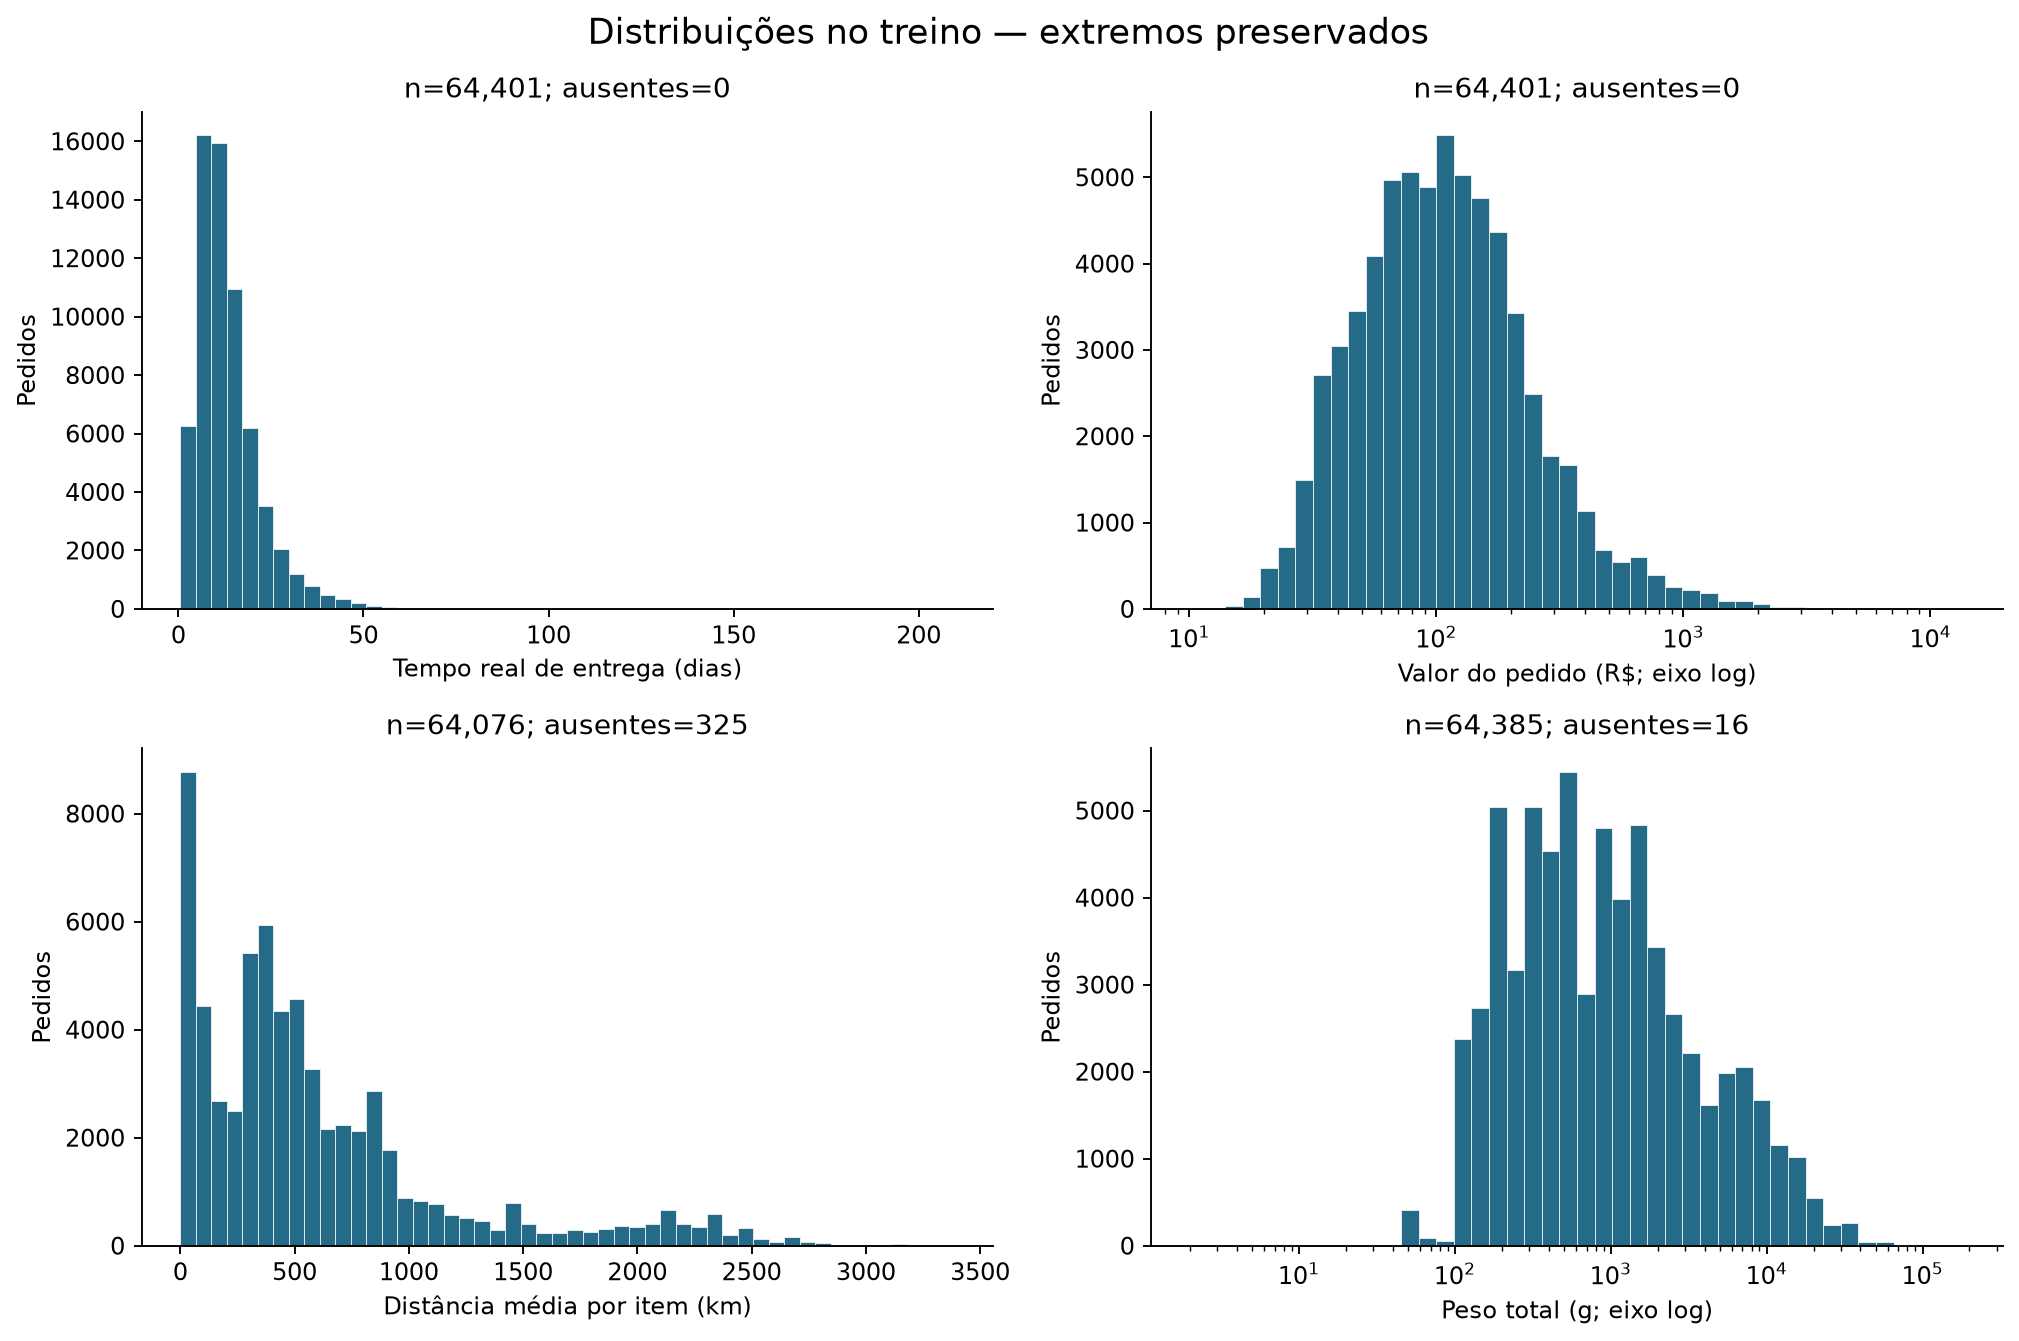

In [3]:
display(pd.read_csv(TABLES / "eda_train_descriptive.csv"))
missing = pd.read_csv(TABLES / "eda_train_missing.csv")
display(missing.loc[missing.missing.gt(0)])
display(pd.read_csv(TABLES / "eda_train_outliers.csv"))
display(pd.read_csv(TABLES / "eda_train_categorical.csv"))
display(Image(filename=str(FIGURES / "01_distributions_train.png"), width=1050))

## Correlações e relações com o alvo

Correlação de Spearman usa apenas pares conhecidos no treino e omite constantes no gráfico. Distâncias mínima/média/máxima compartilham informação. Associações e importâncias não estabelecem causalidade.

,feature,spearman,pearson,abs_spearman
0,distance_km_min,0.534498,0.391528,0.534498
1,distance_km_mean,0.532970,0.390723,0.532970
2,distance_km_max,0.530860,0.389567,0.530860
3,same_state_items_fraction,-0.490375,-0.365985,0.490375
4,freight_value_total,0.405372,0.186294,0.405372
5,order_value_total,0.132839,0.073007,0.132839
6,products_value_total,0.091980,0.058396,0.091980
7,weight_g_mean,0.085754,0.077971,0.085754
8,weight_g_total,0.080227,0.070026,0.080227
9,length_cm_max,0.066295,0.060609,0.066295


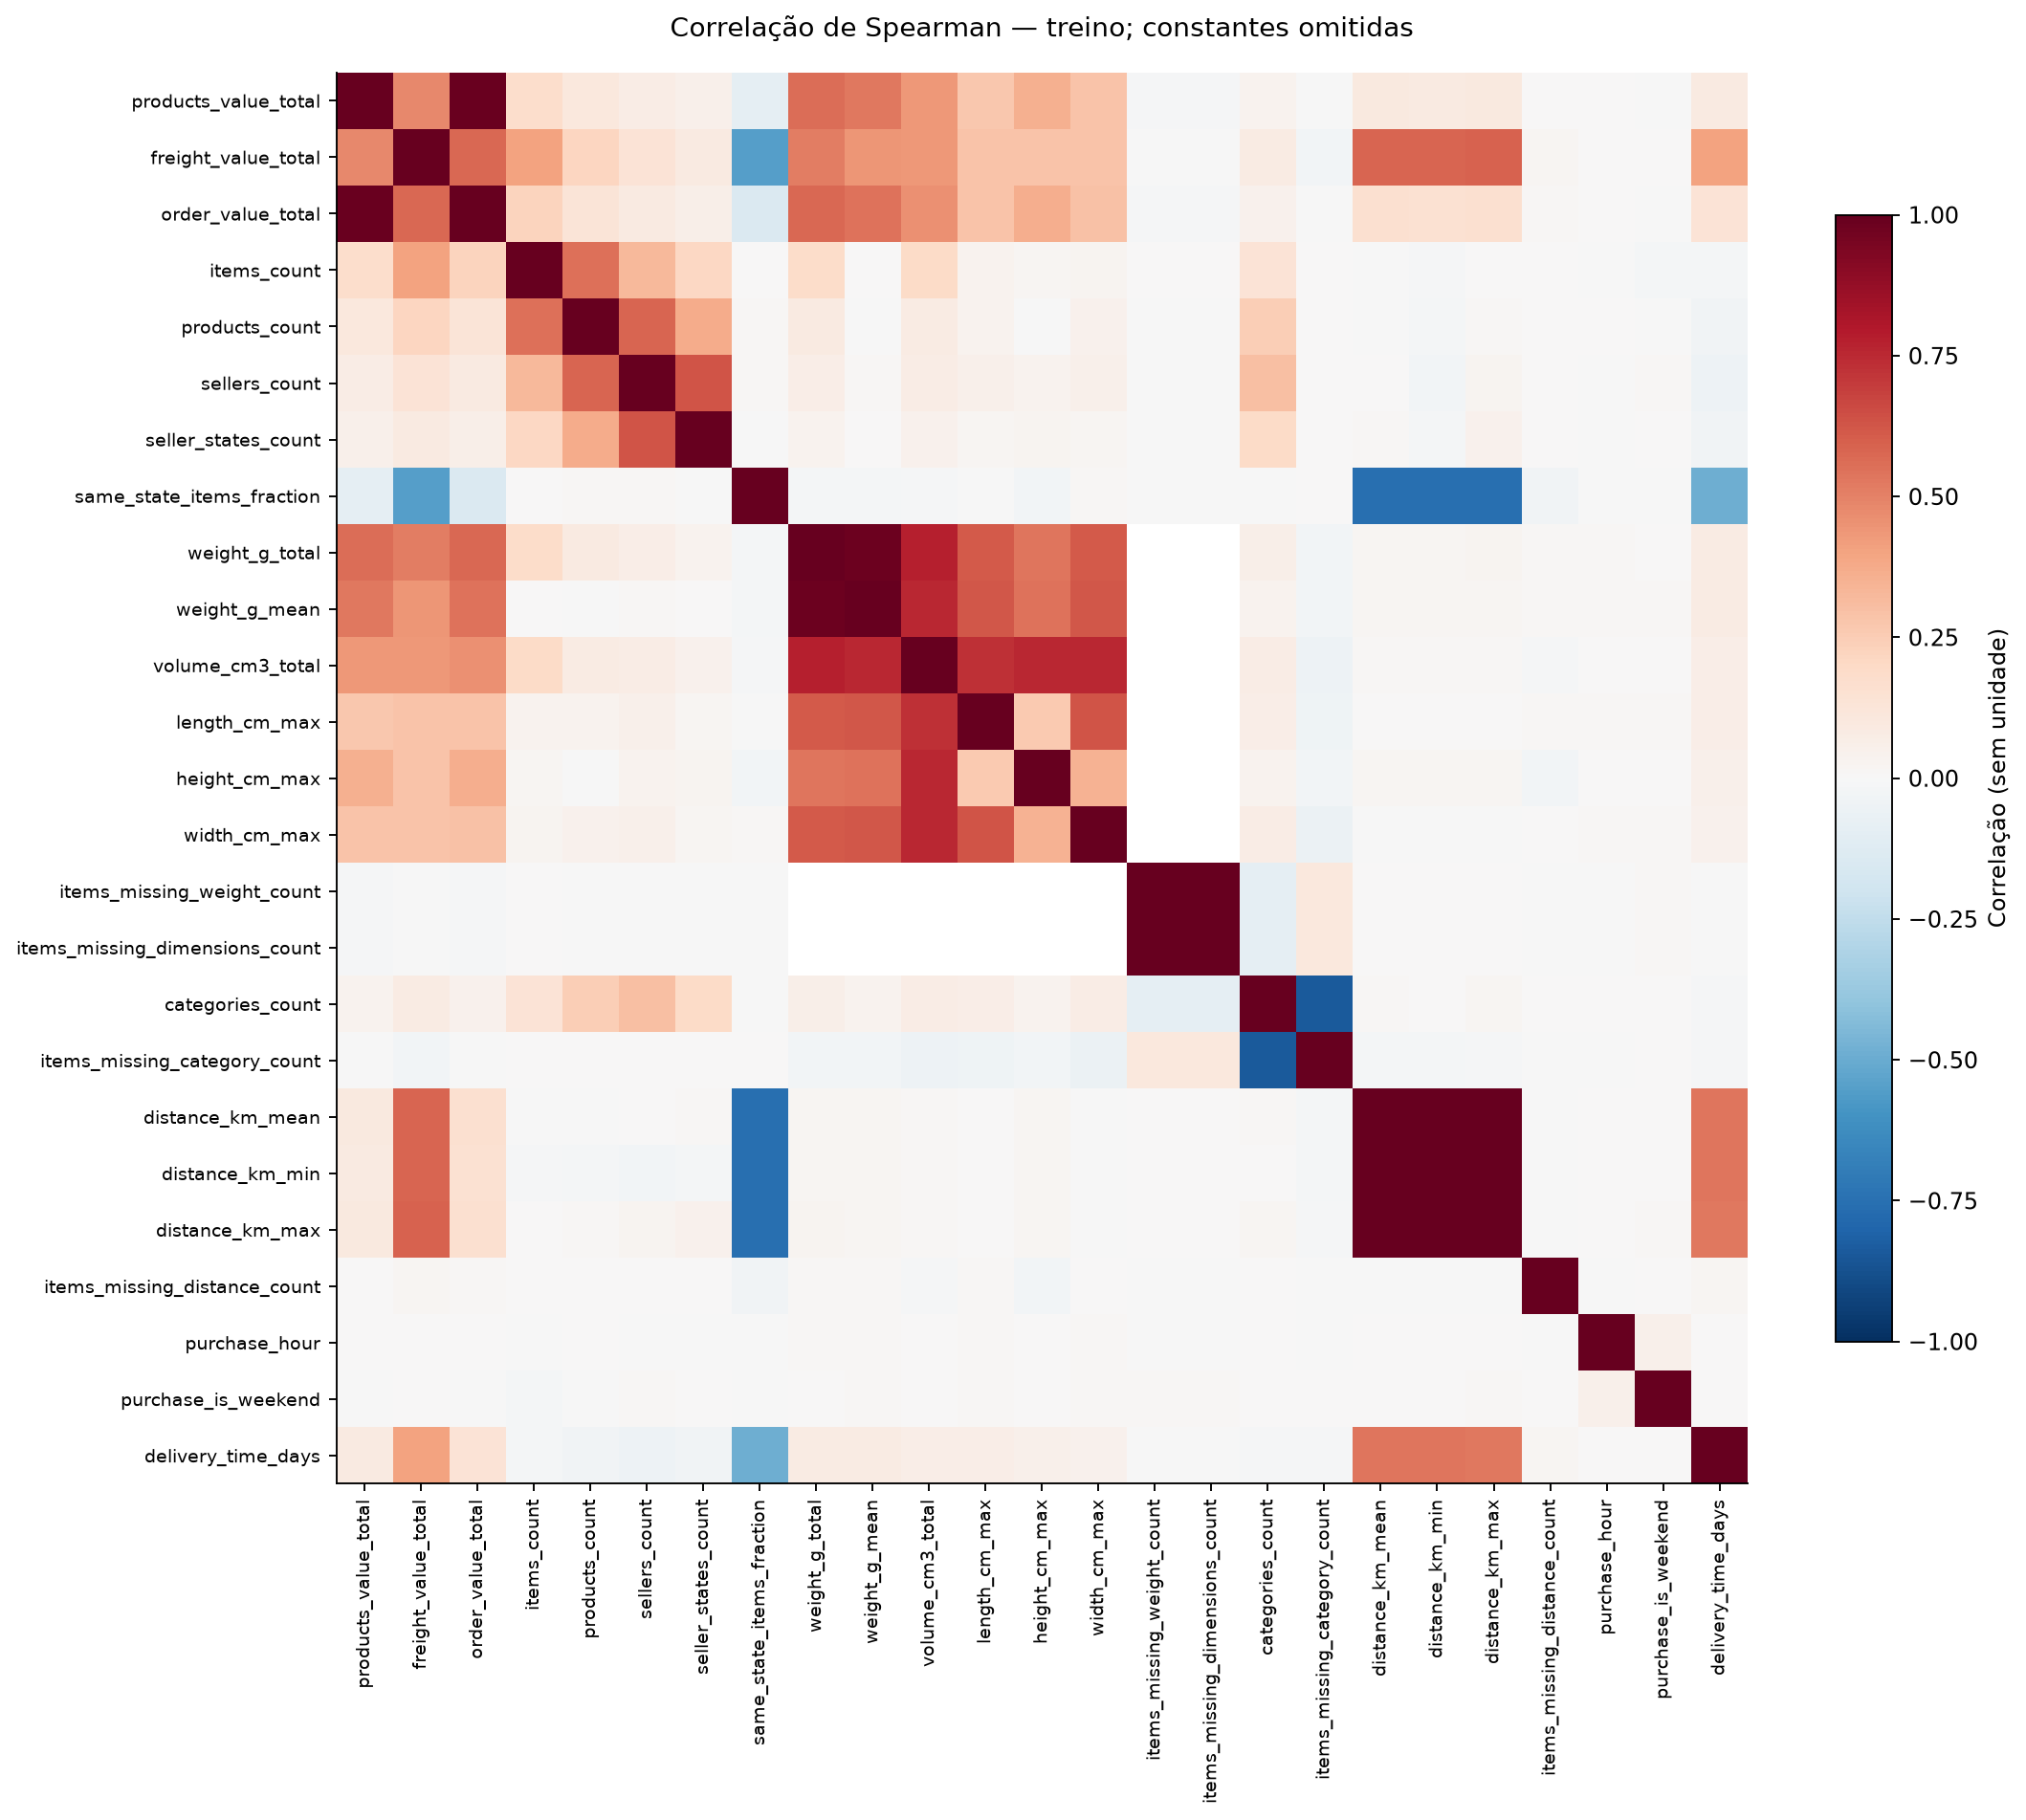

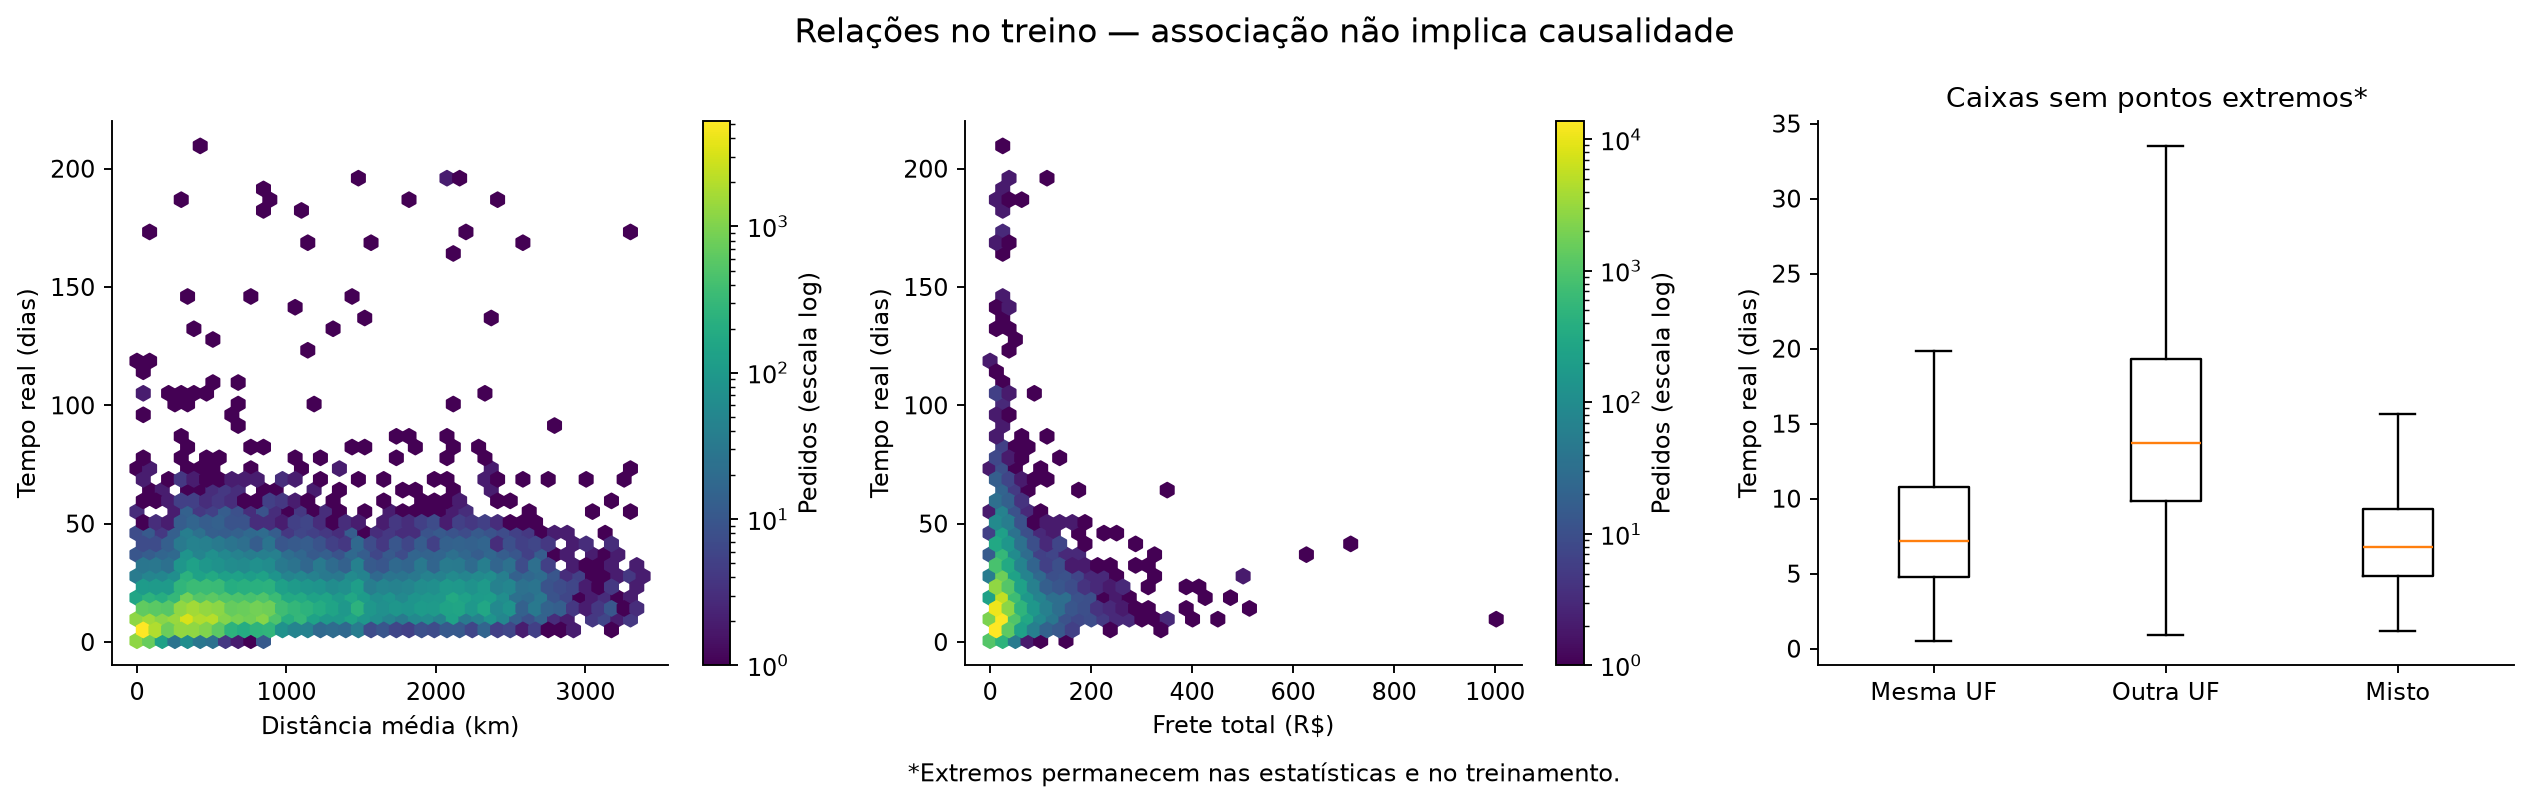

In [4]:
relations = pd.read_csv(TABLES / "eda_train_target_relations.csv")
display(relations)
display(Image(filename=str(FIGURES / "02_correlations_train.png"), width=1100))
display(Image(filename=str(FIGURES / "03_feature_target_train.png"), width=1100))

## Geografia e cobertura temporal

UFs têm amostras diferentes; a dispersão por CEP mostra somente prefixos com pelo menos 20 pedidos. Pontos são aproximações geográficas, sem rotas. Meses sem pedidos aparecem como lacunas. Meses iniciais escassos e o último período afetado pela maturação exigem cautela.

,customer_state,orders,mean_days,median_days,distance_mean_km
0,SP,26428,9.535496,8.001719,249.022878
1,MG,7778,12.846087,11.276447,530.717709
2,PR,3319,12.891625,11.415799,486.635243
3,RJ,8332,15.778317,12.974890,485.090191
4,DF,1341,14.287950,12.993021,825.606190
5,ES,1344,15.892721,14.008044,797.318013
6,MS,467,15.888443,14.148113,843.031538
7,RS,3690,16.346466,14.238495,865.988276
8,SC,2480,16.506025,14.684959,566.470017
9,GO,1344,16.599769,14.809120,776.634043


,month,orders,median_days,q25,q75
0,2016-09,1,54.813194,54.813194,54.813194
1,2016-10,265,17.944282,9.020162,25.678287
2,2016-11,0,NaN,NaN,NaN
3,2016-12,1,4.693021,4.693021,4.693021
4,2017-01,750,10.733646,7.748799,14.028924
5,2017-02,1653,10.971204,7.662234,15.794016
6,2017-03,2546,10.126487,7.025909,14.603889
7,2017-04,2303,12.748623,8.711927,18.037529
8,2017-05,3545,9.793333,6.896597,13.892569
9,2017-06,3135,10.804907,7.358009,14.545498


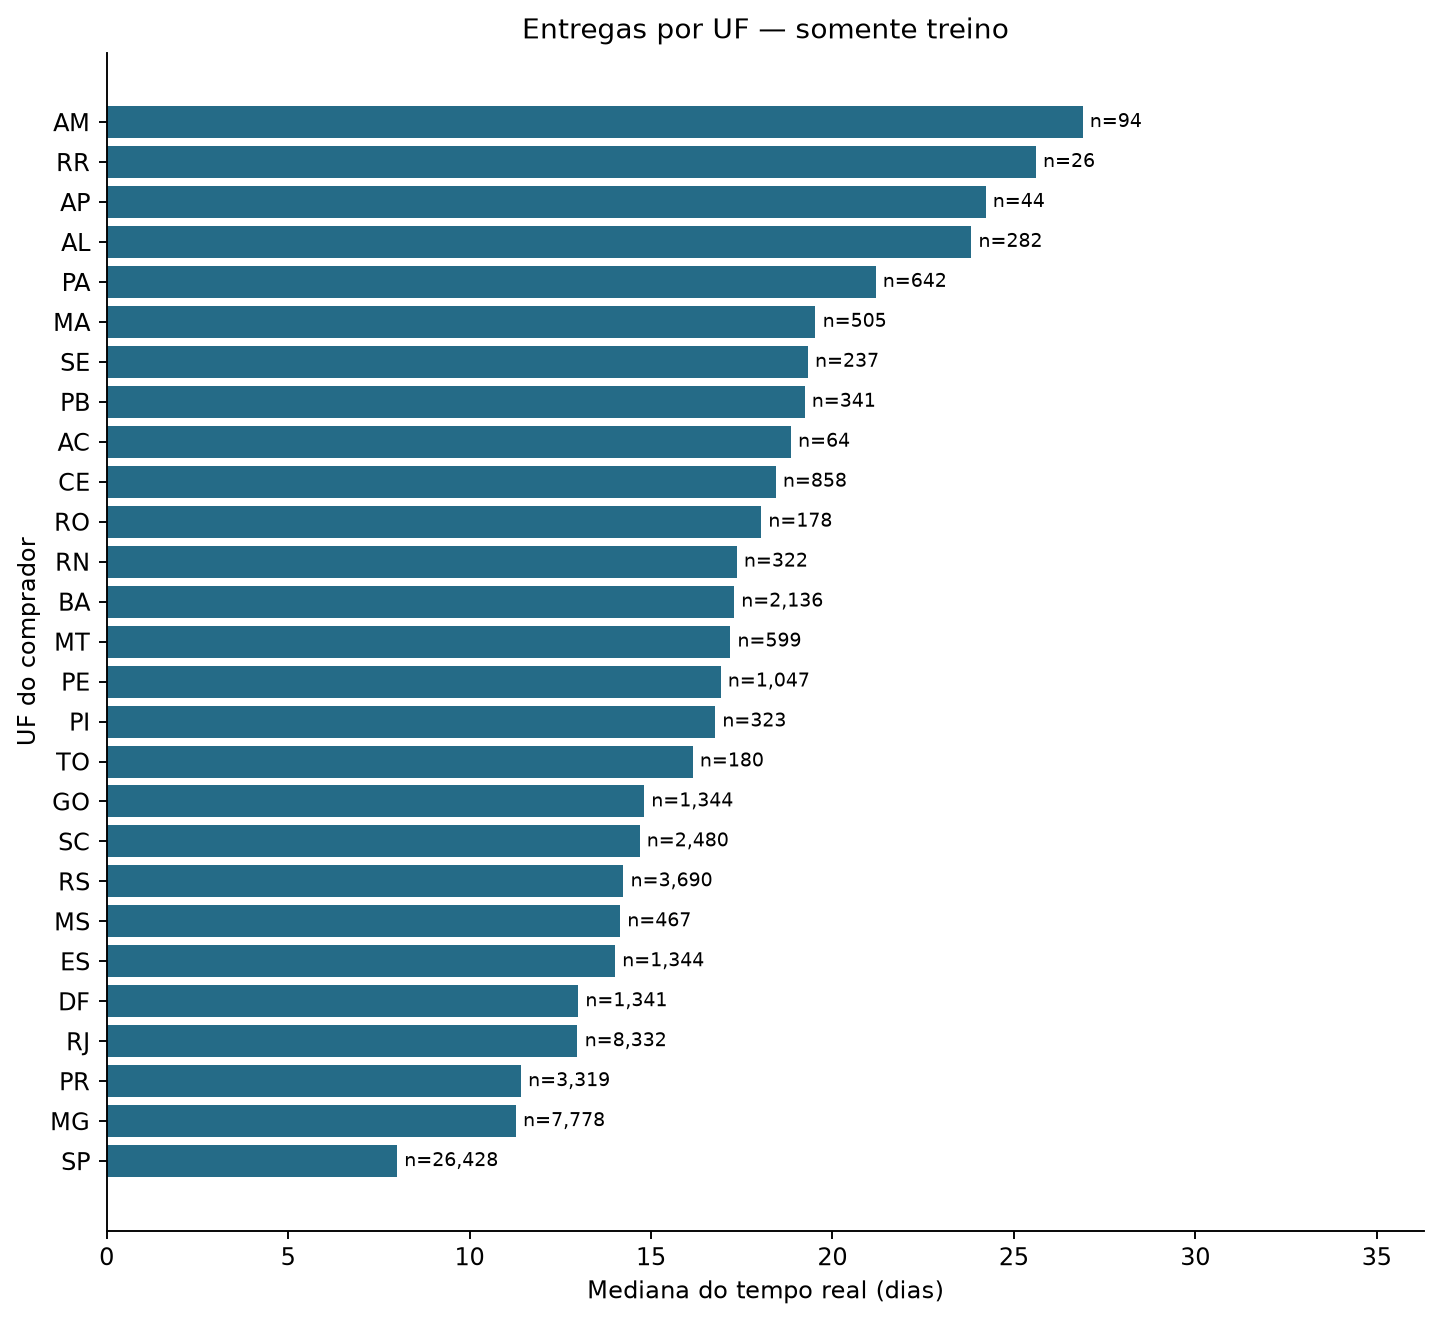

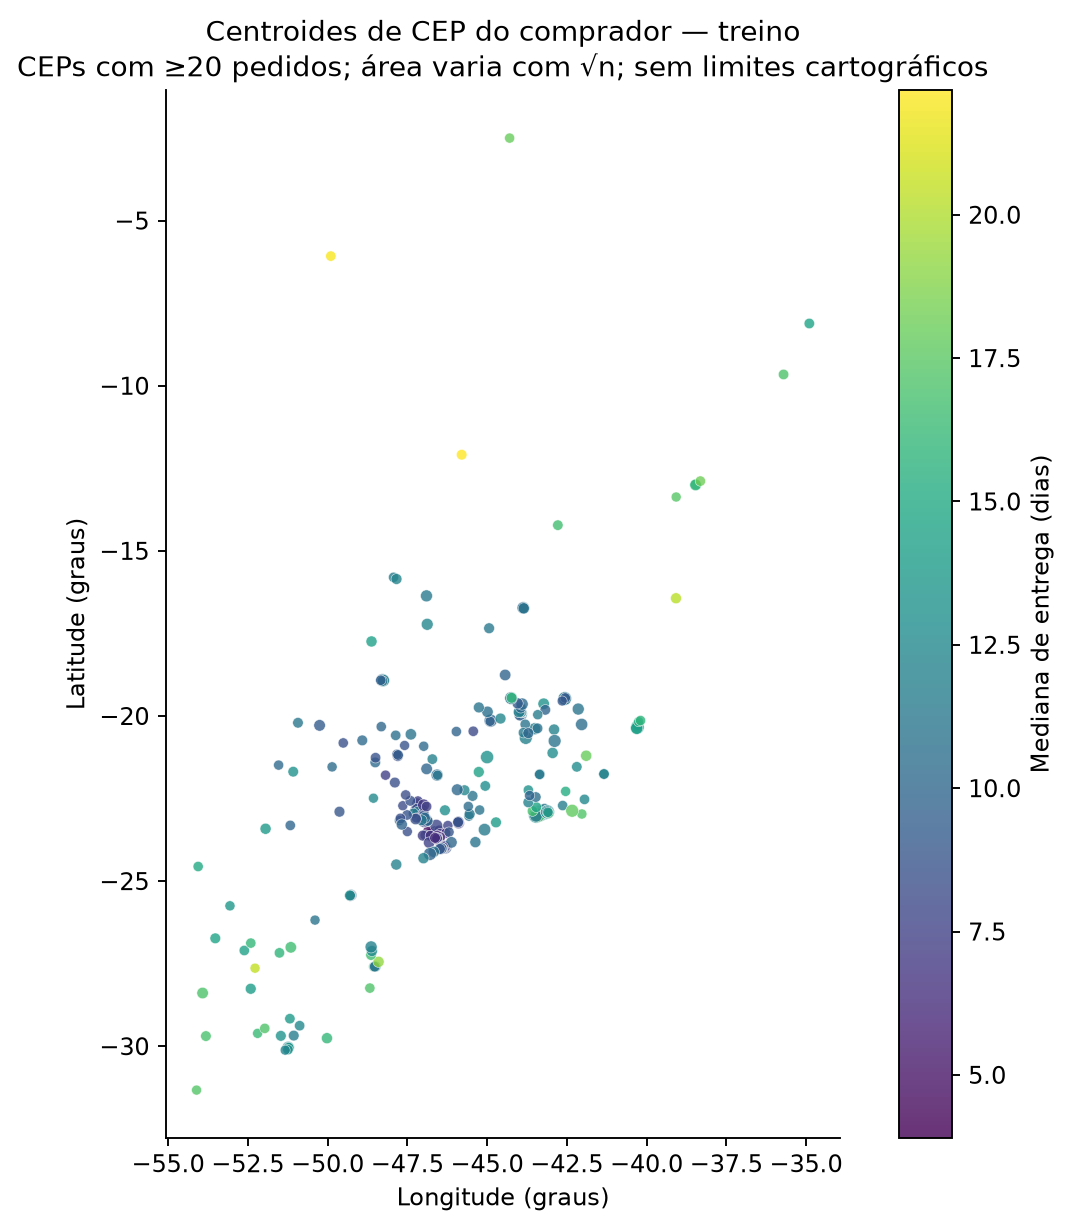

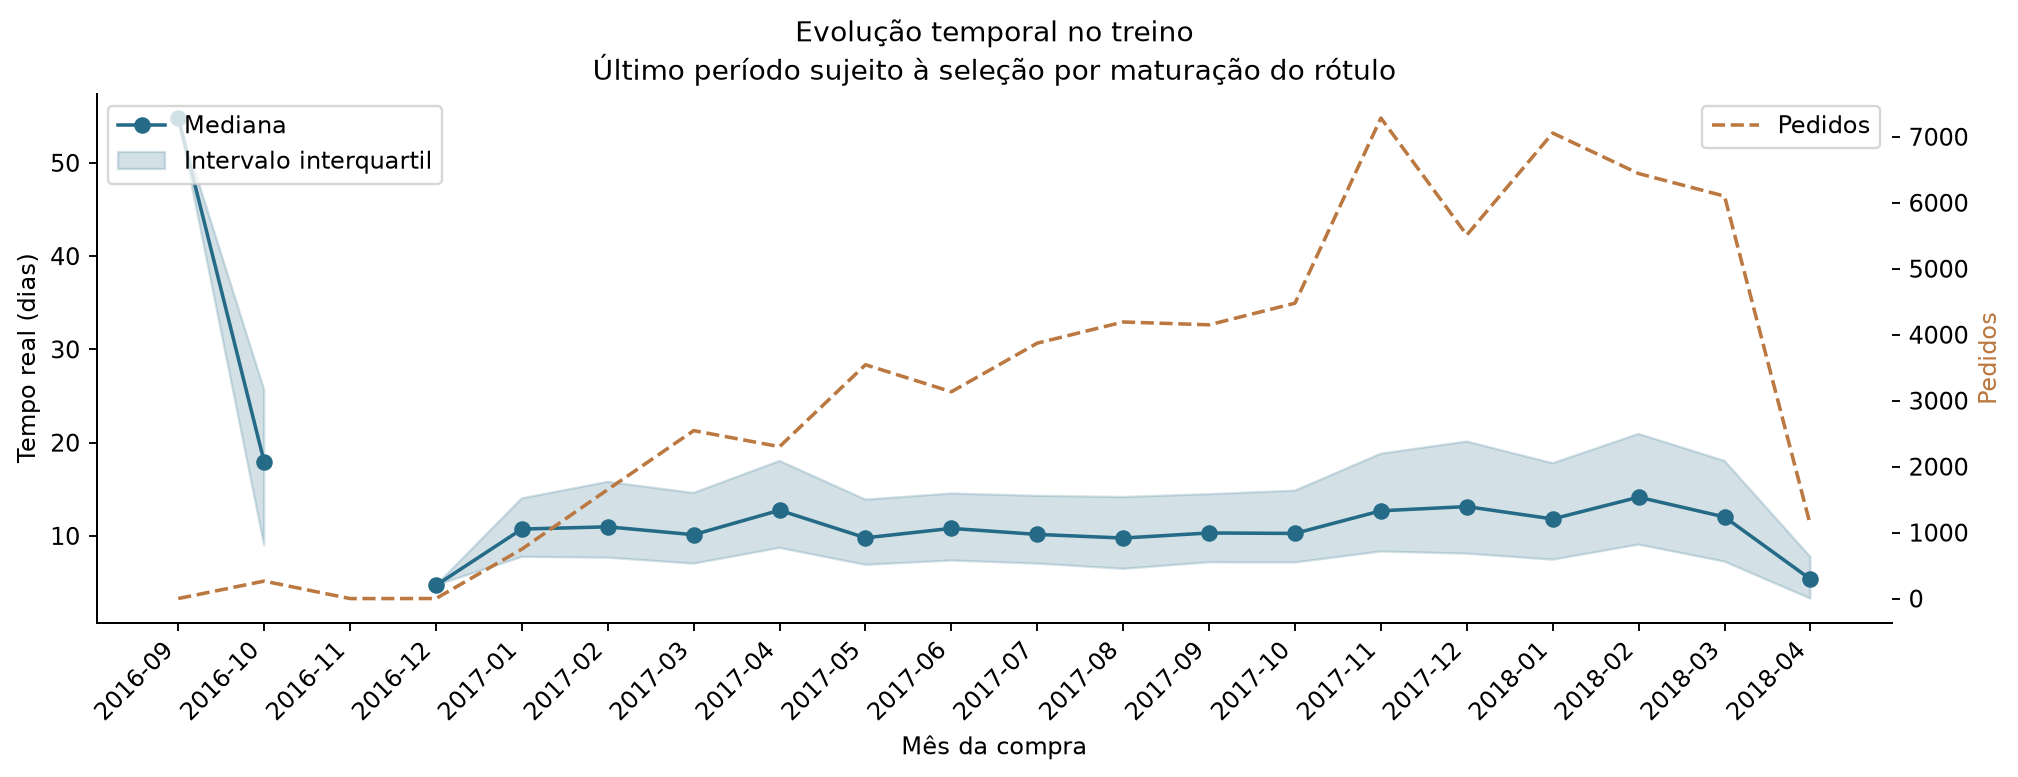

In [5]:
display(pd.read_csv(TABLES / "eda_train_by_state.csv"))
display(pd.read_csv(TABLES / "eda_train_by_month.csv"))
for name in ["04_state_train.png", "05_geographic_train.png", "06_monthly_train.png"]:
    display(Image(filename=str(FIGURES / name), width=1000))

## Interpretação

A distância e o frete apresentam associação positiva com tempo, e mesma UF apresenta associação negativa. Valores exatos estão na tabela acima. Caudas, diferenças regionais e mudanças temporais permanecem, sem atribuição causal. A EDA não usou validação ou teste para escolher tratamentos.